# Leaf Classification: Basil, Chinar and Lemon

# Introduction

The purpose of this task is to classify leaf images into three categories which are Basil, Chinar, and Lemon using supervised machine learning. Given a set of labelled leaf images, the goal is to extract meaningful features from each image and train classifiers that can correctly identify the leaf class of unseen images.

The data consists of RGB images sourced from Kaggle, with approximately 60 images per class totalling 184 images. Each image is processed independently, meaning no sequential or spatial relationships between images are exploited.

Three types of features are extracted from each image. First-order color features capture the mean and variance of each RGB channel, giving 6 features per image. Second-order texture features are derived from the Gray-Level Co-occurrence Matrix, capturing how pixel intensities relate to their neighbours in horizontal and vertical directions at two different distances, giving 4 features. Finally, template matching scores measure how similar each image is to a representative template from each class, giving 3 additional features. This results in a total of 13 features per image.

Three machine learning classifiers are trained and evaluated: Ridge Classifier, a linear model with L2 regularization; Random Forest, an ensemble of decision trees using bootstrap sampling; and a Multi-Layer Perceptron, a neural network with one hidden layer. Hyperparameters for each classifier are selected using GridSearchCV with Stratified K-Fold cross-validation. Final performance is estimated using nested cross-validation to obtain an unbiased accuracy estimate for each model.

# Data Preparation

In [1]:
# Standard library
import os

# Data handling
import numpy as np
import pandas as pd

# Image processing
import cv2
from skimage import feature, color
import mahotas.features

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import scatter_matrix


# Scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

from scipy.spatial.distance import cdist


In [2]:
#Data Preparation 

# Leaf class folders (label index: Basil=0, Chinar=1, Lemon=2)
folders = ['Basil', 'Chinar', 'Lemon']
data = []

# 1. Load images
for label, folder in enumerate(folders):
    for img_file in os.listdir(folder):
        img_path = os.path.join(folder, img_file)
        img_bgr = cv2.imread(img_path)

        if img_bgr is not None:
            # OpenCV loads in BGR by default -> convert to RGB
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            data.append({'image': img_rgb, 'label': label, 'class': folder})

# Verify: print total and per-class image counts
print(f"Total images loaded: {len(data)}")
for folder in folders:
    count = sum(1 for item in data if item['class'] == folder)
    print(f"  {folder}: {count} images")

Total images loaded: 184
  Basil: 60 images
  Chinar: 62 images
  Lemon: 62 images


In [3]:
# 2. Convert to grayscale and reduce quantization to 8 levels [0, 7]
for item in data:
    gray = cv2.cvtColor(item['image'], cv2.COLOR_RGB2GRAY)
    item['gray'] = gray

    # 256 intensity values ÷ 32 = 8 bins
    item['quantized'] = (gray // 32).astype(np.uint8)

# Feature Extraction

## First-order color features (6 features)

In [4]:
# First-order features: mean and variance per RGB channel (6 features total)
for item in data:
    img = item['image']

    # axis=(0,1) averages over height and width, leaving one value per channel
    means     = np.mean(img, axis=(0, 1))
    variances = np.var(img,  axis=(0, 1))

    # Feature vector: [mean_R, mean_G, mean_B, var_R, var_G, var_B]
    item['color_features'] = np.concatenate([means, variances])

# Verify: one sample per class
print(f"Color features extracted from shape: {data[0]['color_features'].shape}")
for folder in folders:
    sample = next(item for item in data if item['class'] == folder)
    print(f"  {sample['class']}: {np.round(sample['color_features'], 2)}")

Color features extracted from shape: (6,)
  Basil: [ 45.44  50.12  41.88 347.93 862.55 146.04]
  Chinar: [ 58.46  67.16  60.93 449.38 933.6  359.97]
  Lemon: [ 47.3   50.63  45.09 280.54 573.37 116.77]


## Second-order texture features (GLCM)

In [5]:
# Second-order features: GLCM correlation in horizontal (0°) and vertical (90°)
# directions at two distances → 4 features per image
# mahotas.haralick returns shape (4 directions, 13 features)
# Direction index: 0=0°, 2=90° | Feature index 2 = correlation

for item in data:
    img = item['quantized']

    features_d1 = mahotas.features.haralick(img, distance=1)
    features_d2 = mahotas.features.haralick(img, distance=2)

    item['glcm_d1_h'] = features_d1[0, 2]  # distance 1, horizontal
    item['glcm_d1_v'] = features_d1[2, 2]  # distance 1, vertical
    item['glcm_d2_h'] = features_d2[0, 2]  # distance 2, horizontal
    item['glcm_d2_v'] = features_d2[2, 2]  # distance 2, vertical

# Verify: one sample per class
print("GLCM correlations (one sample per class):")
for folder in folders:
    sample = next(item for item in data if item['class'] == folder)
    print(f"  {sample['class']}: d1_h={sample['glcm_d1_h']:.4f}, d1_v={sample['glcm_d1_v']:.4f}, "
          f"d2_h={sample['glcm_d2_h']:.4f}, d2_v={sample['glcm_d2_v']:.4f}")

GLCM correlations (one sample per class):
  Basil: d1_h=0.9592, d1_v=0.9504, d2_h=0.9297, d2_v=0.9103
  Chinar: d1_h=0.9347, d1_v=0.9029, d2_h=0.8755, d2_v=0.8227
  Lemon: d1_h=0.9502, d1_v=0.9137, d2_h=0.9037, d2_v=0.8394


## GLCM Correlation Feature

The correlation feature from the GLCM measures the linear dependency of gray levels 
in the image. It quantifies how much the gray levels of neighboring pixels are related:

- High correlation: (close to 1): Gray levels are strongly related; 
  the image has organized structure and patterns
- Low correlation: (close to -1 or 0): Gray levels are weakly related; 
  the image appears random or lacks texture patterns

For leaf classification, this helps distinguish between different leaf surface textures 
and patterns (e.g., smooth vs. textured leaves).

## Template-matching features

In [6]:

# Select one representative template per class (image closest to class centroid)
templates = {}
for folder in folders:
    class_features = [item['color_features'] for item in data if item['class'] == folder]
    centroid = np.mean(class_features, axis=0)
    distances = cdist([centroid], class_features)[0]
    closest_item = [item for item in data if item['class'] == folder][np.argmin(distances)]
    templates[folder] = closest_item['gray']  # use grayscale for matching

# Compute normalized cross-correlation score against each class template
# 3 scores per image (one per class), stored as feature vector
for item in data:
    img = item['gray']
    scores = []
    for class_name, template in templates.items():
        t_resized = cv2.resize(template, (img.shape[1], img.shape[0]))
        result = cv2.matchTemplate(img, t_resized, cv2.TM_CCOEFF_NORMED)
        scores.append(np.max(result))
    item['template_features'] = np.array(scores) 

# Verify: one sample per class
print("Template matching scores [Basil, Chinar, Lemon]:")
for folder in folders:
    sample = next(item for item in data if item['class'] == folder)
    print(f"  {sample['class']}: {np.round(sample['template_features'], 4)}")

Template matching scores [Basil, Chinar, Lemon]:
  Basil: [0.7789 0.4952 0.5807]
  Chinar: [0.5603 0.5891 0.6021]
  Lemon: [0.6875 0.4655 0.7435]


## Template Matching Feature

Template matching compares each image against representative templates from each class. 
It measures how similar a leaf image is to typical leaf examples using normalized 
cross-correlation:

- **High score** (close to 1): The image is very similar to the template; 
  likely belongs to that class
- **Low score** (close to 0): The image is dissimilar to the template; 
  unlikely to belong to that class

For leaf classification, this feature captures structural and shape similarity
to each leaf type. By computing the maximum matching score across all class templates, 
we identify which template the image most closely resembles, providing a strong 
discriminative feature for classification.

# Feature Relationships

## Pairplot

Total features: 13 | Total images: 184


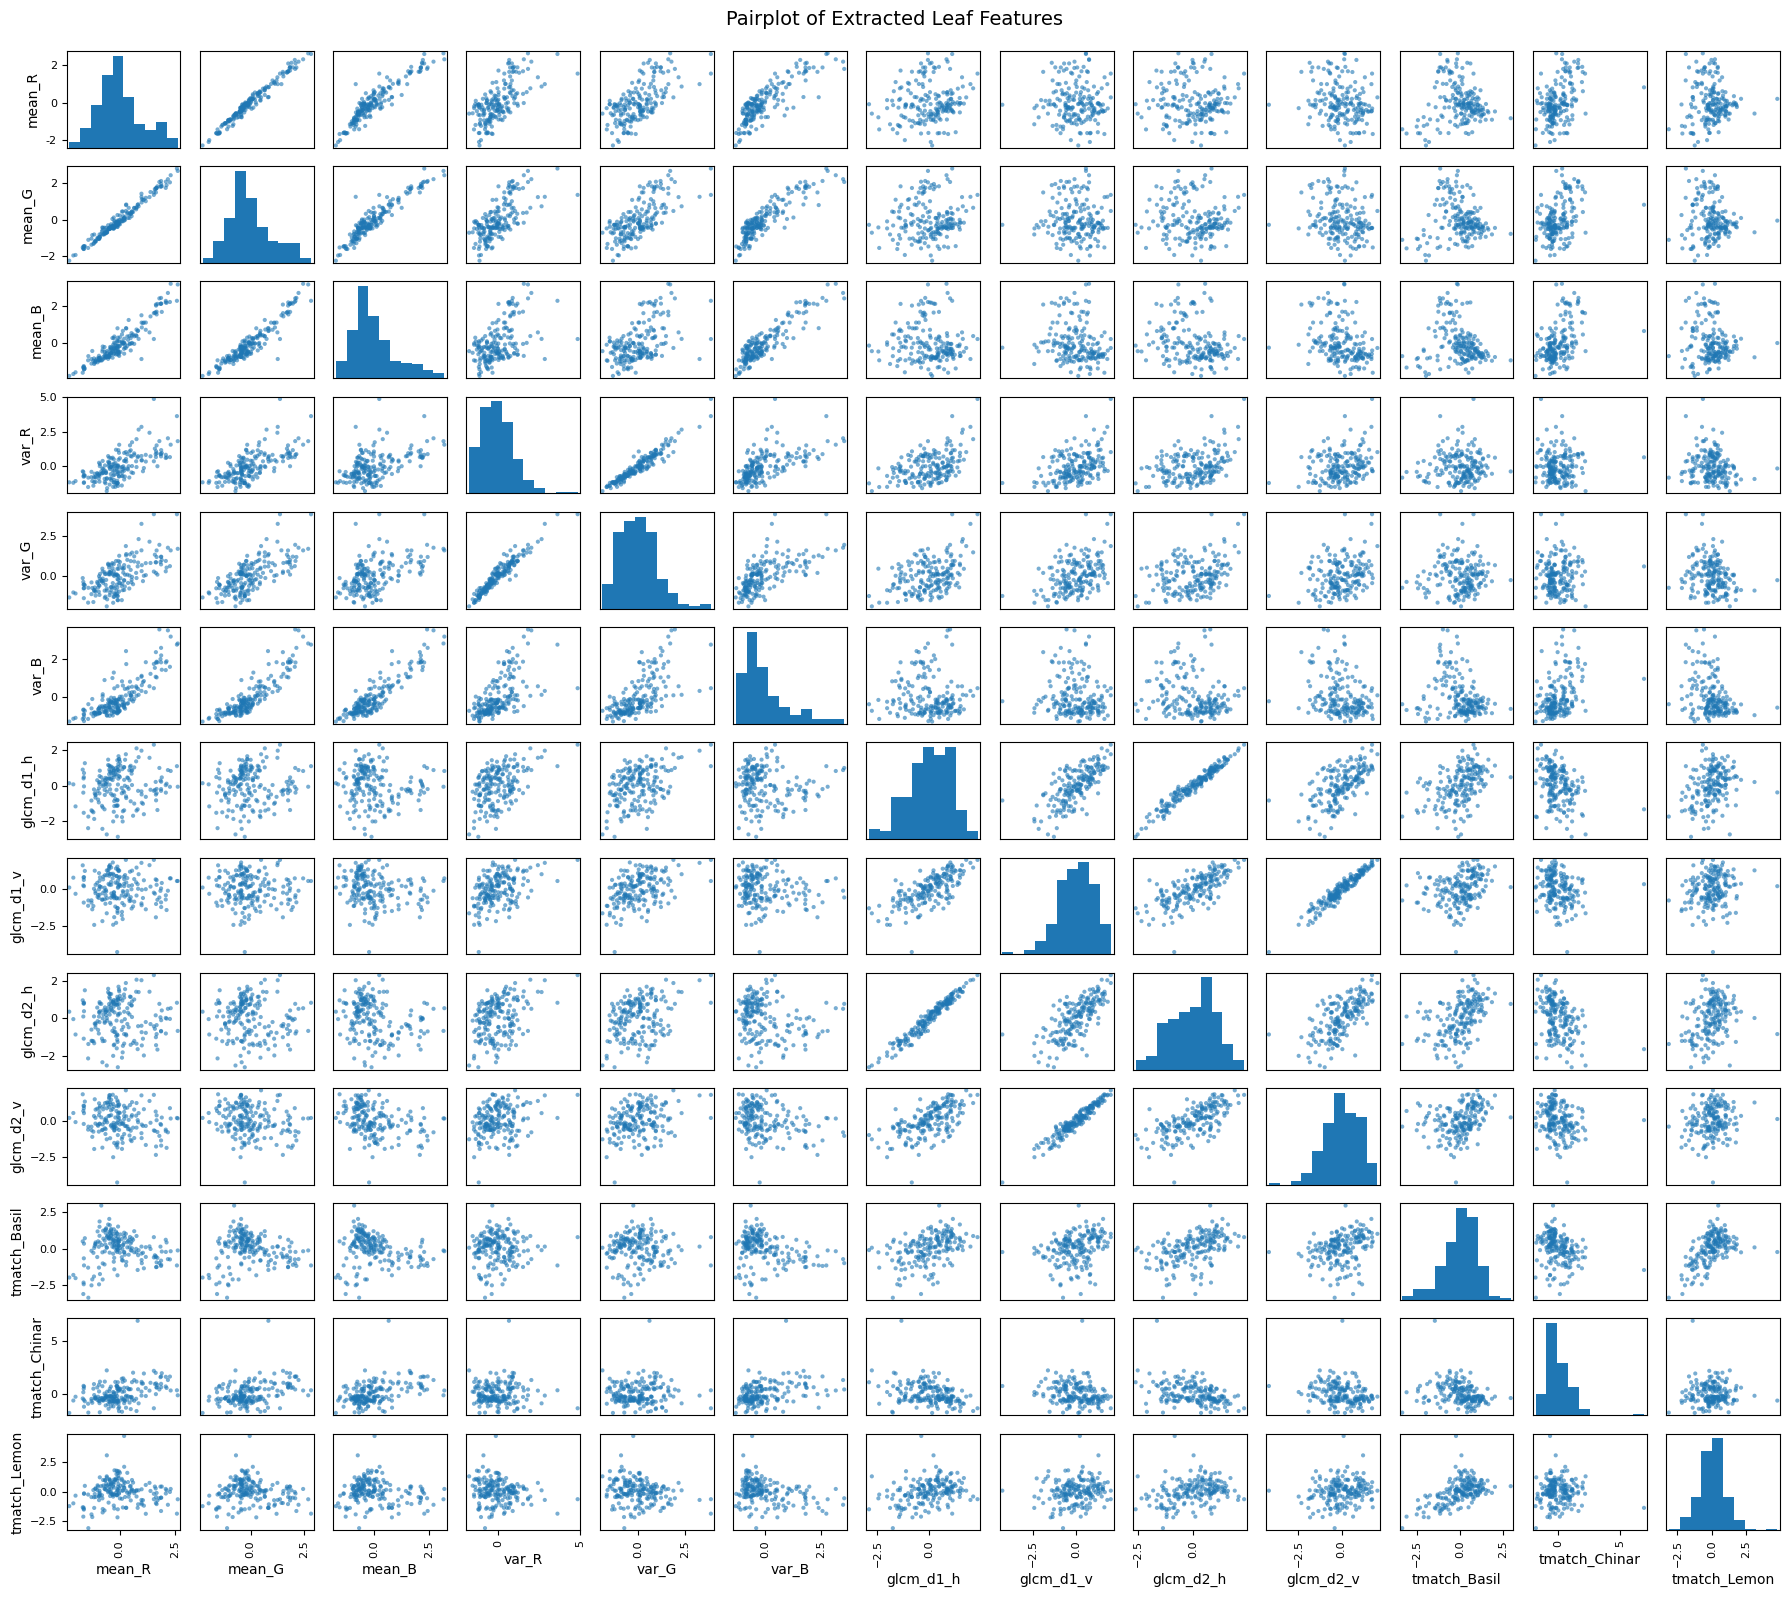


Correlation Matrix:
               mean_R  mean_G  mean_B  var_R  var_G  var_B  glcm_d1_h  \
mean_R          1.000   0.986   0.929  0.668  0.644  0.839      0.137   
mean_G          0.986   1.000   0.944  0.682  0.695  0.891      0.100   
mean_B          0.929   0.944   1.000  0.500  0.508  0.908     -0.065   
var_R           0.668   0.682   0.500  1.000  0.958  0.608      0.471   
var_G           0.644   0.695   0.508  0.958  1.000  0.647      0.422   
var_B           0.839   0.891   0.908  0.608  0.647  1.000     -0.046   
glcm_d1_h       0.137   0.100  -0.065  0.471  0.422 -0.046      1.000   
glcm_d1_v      -0.030  -0.031  -0.182  0.420  0.432 -0.118      0.704   
glcm_d2_h      -0.019  -0.057  -0.221  0.368  0.321 -0.186      0.976   
glcm_d2_v      -0.190  -0.191  -0.332  0.260  0.284 -0.269      0.615   
tmatch_Basil   -0.002  -0.061  -0.196  0.034  0.015 -0.269      0.430   
tmatch_Chinar   0.403   0.394   0.440  0.005  0.018  0.370     -0.329   
tmatch_Lemon    0.005  -0.089 

In [7]:
# Build DataFrame with all 13 features + class label
feature_list = []
for item in data:
    row = {
        'mean_R': item['color_features'][0],
        'mean_G': item['color_features'][1],
        'mean_B': item['color_features'][2],
        'var_R':  item['color_features'][3],
        'var_G':  item['color_features'][4],
        'var_B':  item['color_features'][5],
        'glcm_d1_h': item['glcm_d1_h'],
        'glcm_d1_v': item['glcm_d1_v'],
        'glcm_d2_h': item['glcm_d2_h'],
        'glcm_d2_v': item['glcm_d2_v'],
        'tmatch_Basil':  item['template_features'][0],
        'tmatch_Chinar': item['template_features'][1],
        'tmatch_Lemon':  item['template_features'][2],
        'class': item['class']
    }
    feature_list.append(row)

df = pd.DataFrame(feature_list)

feature_cols = ['mean_R', 'mean_G', 'mean_B', 'var_R', 'var_G', 'var_B',
                'glcm_d1_h', 'glcm_d1_v', 'glcm_d2_h', 'glcm_d2_v',
                'tmatch_Basil', 'tmatch_Chinar', 'tmatch_Lemon']

print(f"Total features: {len(feature_cols)} | Total images: {len(df)}")

# Standardize features for visualization
scaler = StandardScaler()
df[feature_cols] = scaler.fit_transform(df[feature_cols])

# Pairplot
scatter_matrix(df[feature_cols], alpha=0.6, figsize=(18, 16), diagonal='hist')
plt.suptitle('Pairplot of Extracted Leaf Features', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

# Correlation matrix
print("\nCorrelation Matrix:")
print(df[feature_cols].corr().round(3))

## Feature Pairs with Strong Linear Dependence

Based on visual inspection of the pairplot, the following feature pairs show 
approximately linear dependence(tight diagonal scatter patterns):

### Strong Linear Dependencies:
- mean_R - mean_G: 0.986 - nearly perfect, color channels move together
- mean_G - mean_B: 0.944 - strong, consistent across channels
- mean_R - mean_B: 0.929 - strong
- var_R - var_G: 0.958 - variance is consistent across R and G channels
- glcm_d1_h - glcm_d2_h: 0.976 - fine and coarse horizontal texture are redundant
- glcm_d1_v - glcm_d2_v: 0.961 - same for vertical direction

### Weak Linear Dependencies (scattered patterns):
- var_R/G/B vs other groups: moderate at best
- template_matching features: largely independent from color and texture features

Color channel means are highly redundant with each other, as are GLCM features within the same direction. 

## Histograms

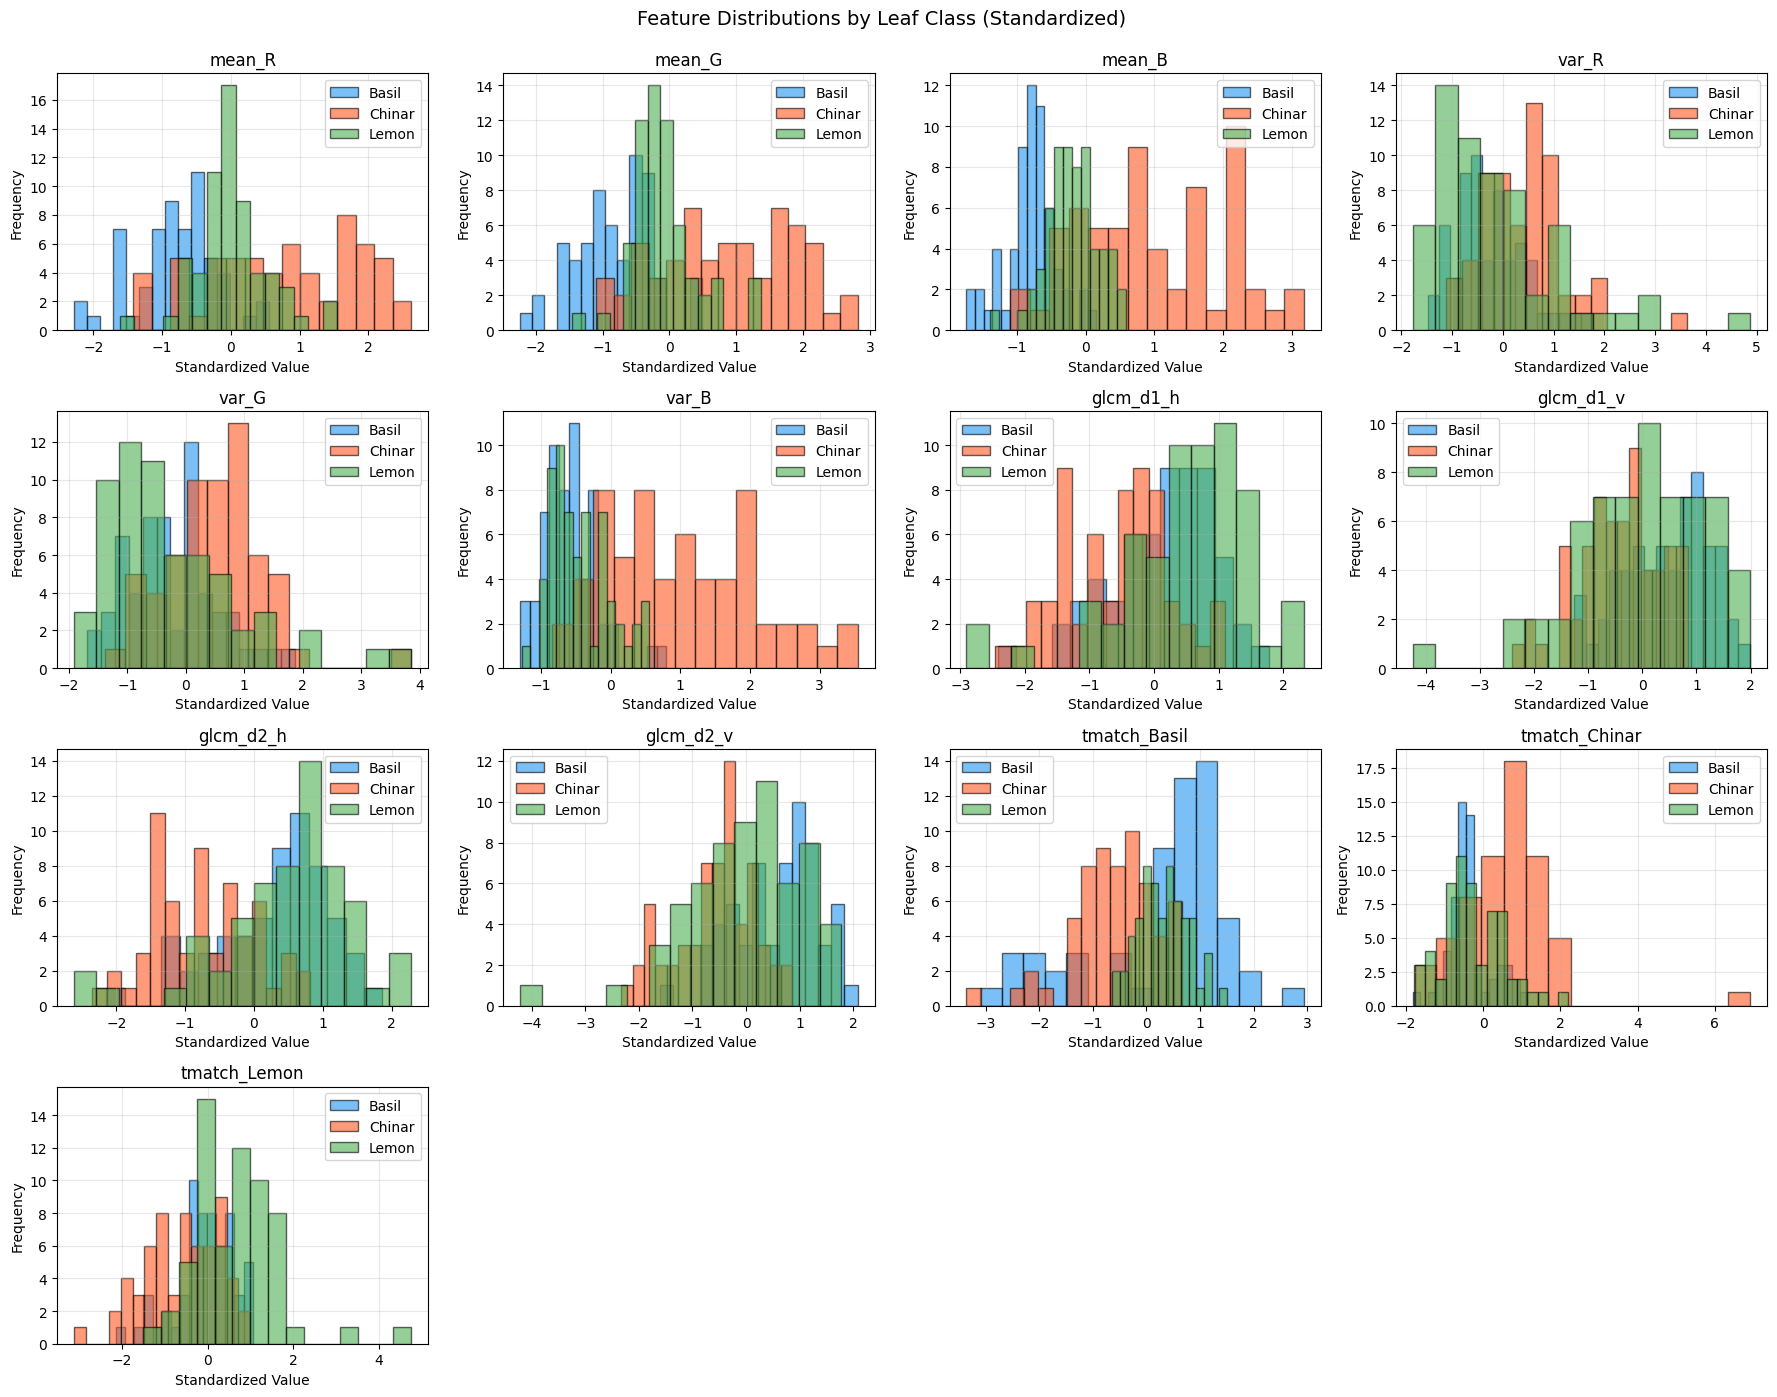

In [8]:
feature_cols = ['mean_R', 'mean_G', 'mean_B', 'var_R', 'var_G', 'var_B',
                'glcm_d1_h', 'glcm_d1_v', 'glcm_d2_h', 'glcm_d2_v',
                'tmatch_Basil', 'tmatch_Chinar', 'tmatch_Lemon']

# Features already standardized previously

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.flatten()
colors = {'Basil': '#2196F3', 'Chinar': '#FF5722', 'Lemon': '#4CAF50'}

for idx, feature in enumerate(feature_cols):
    ax = axes[idx]
    for class_name, color in colors.items():
        class_data = df[df['class'] == class_name][feature]
        ax.hist(class_data, bins=15, alpha=0.6, label=class_name, color=color, edgecolor='black')
    ax.set_xlabel('Standardized Value')
    ax.set_ylabel('Frequency')
    ax.set_title(feature)
    ax.legend()
    ax.grid(alpha=0.3)

# Hide unused subplots (13 features, 16 slots)
for idx in range(len(feature_cols), len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Feature Distributions by Leaf Class (Standardized)', fontsize=14, y=0.995)
plt.tight_layout()
plt.show()

## Feature Discriminative Power Analysis

### High Discriminative Power:

- mean_R, mean_G, mean_B - clear separation across all three classes, distributions are visibly shifted from each other

- tmatch_Chinar - Chinar strongly shifted right (high scores ~2–6), Basil and Lemon concentrated low; excellent for identifying Chinar

- tmatch_Basil - Basil shifted right relative to others, moderate-good separation

### Moderate Discriminative Power:

- var_R, var_B - Lemon tends higher, some separation but notable overlap

- var_G - Lemon concentrated at lower values, partial separation

- tmatch_Lemon - Lemon slightly shifted right but classes still overlap considerably

- glcm_d2_h - moderate separation, Basil concentrated on the left and Lemon shifted right; more useful than the other GLCM features

### Low Discriminative Power (poor separation):


- glcm_d1_h, glcm_d1_v, glcm_d2_v: all three classes heavily overlap, nearly indistinguishable individually

Conclusion: 
Color means are the strongest discriminators. The Chinar template score adds strong shape-based discrimination specifically for that class. GLCM features vary in usefulness. Glcm_d2_h shows genuine separation between Basil and Lemon, while the remaining GLCM features contribute little individually.

## PCA

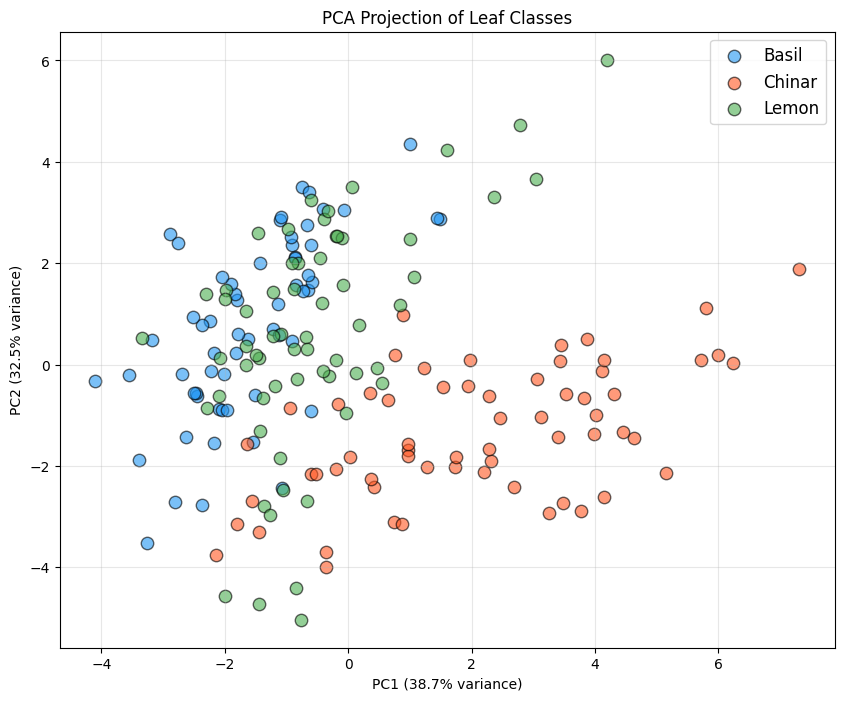

Variance explained by PC1: 0.387
Variance explained by PC2: 0.325
Total variance explained:  0.712


In [9]:
# PCA on-standardized features
pca = PCA(n_components=2)
pca_features = pca.fit_transform(df[feature_cols])

pca_df = pd.DataFrame({
    'PC1': pca_features[:, 0],
    'PC2': pca_features[:, 1],
    'class': df['class']
})

colors = {'Basil': '#2196F3', 'Chinar': '#FF5722', 'Lemon': '#4CAF50'}

plt.figure(figsize=(10, 8))
for class_name, color in colors.items():
    class_data = pca_df[pca_df['class'] == class_name]
    plt.scatter(class_data['PC1'], class_data['PC2'],
                label=class_name, color=color, s=80, alpha=0.6, edgecolors='black')

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
plt.title('PCA Projection of Leaf Classes')
plt.legend(fontsize=12)
plt.grid(alpha=0.3)
plt.show()

print(f"Variance explained by PC1: {pca.explained_variance_ratio_[0]:.3f}")
print(f"Variance explained by PC2: {pca.explained_variance_ratio_[1]:.3f}")
print(f"Total variance explained:  {sum(pca.explained_variance_ratio_):.3f}")

## PCA Analysis and Classification Insights

### Cluster Observations:

- Basil (blue): Concentrated on the left side (PC1 ≈ -5 to -1), forming a reasonably distinct cluster with moderate vertical spread. Some overlap with Lemon in the center region.
- Chinar (orange): Spread across the right side (PC1 ≈ -2 to 7), clearly shifted right along PC1. Best-separated class overall, though with considerable internal spread vertically.
- Lemon (green): Scattered broadly across the center-left region, overlapping substantially with both Basil and Chinar. The least distinct cluster of the three.

### Variance Explained:
- PC1 (38.7%): Captures the primary variation, mainly separating Chinar from the other two classes along the horizontal axis.
- PC2 (32.5%): Captures secondary variation but adds limited additional class separation.
- Total (71.2%): Two components capture about 71% of feature variance which is reasonable but not dominant, suggesting the remaining features still carry useful information.

### What PCA suggests about classification performance:

Chinar should classify better due to its clear rightward shift along PC1. Basil has reasonable separation from Chinar but overlaps with Lemon in the center. Lemon is the most challenging class with no clear cluster boundary. Overall moderate accuracy is expected and classifiers will likely struggle most with Basil vs. Lemon misclassifications.

# Classifiers and Hyperparameter Selection

Stratified K-Fold cross-validation with GridSearchCV.

In [10]:
# Prepare feature matrix and label vector
X = df[feature_cols].values
y = df['class'].values

# Encode string labels to numeric (used consistently by all classifiers)
le = LabelEncoder()
y_encoded = le.fit_transform(y)  # Basil=0, Chinar=1, Lemon=2

# Stratified K-Fold ensures each fold has the same class distribution
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=15)

# Dictionary to store best models and results
results = {}

print(f"Feature matrix X: {X.shape}")
print(f"Label vector y:   {y.shape}")
print(f"Class distribution: { {folder: list(y).count(folder) for folder in folders} }")


Feature matrix X: (184, 13)
Label vector y:   (184,)
Class distribution: {'Basil': 60, 'Chinar': 62, 'Lemon': 62}


## Ridge Classifier

In [11]:
# Ridge Classifier  linear model with L2 regularization
# alpha controls regularization strength: smaller = less regularized
param_grid_ridge = {'alpha': [0.001, 0.01, 0.1, 1.0]}

ridge = RidgeClassifier()
grid_ridge = GridSearchCV(ridge, param_grid_ridge, cv=skf, scoring='accuracy', n_jobs=-1)
grid_ridge.fit(X, y_encoded)

results['Ridge'] = {
    'model':    grid_ridge.best_estimator_,
    'accuracy': grid_ridge.best_score_,
    'params':   grid_ridge.best_params_
}
print("Ridge Classifier")
print(f"  Best params:               {grid_ridge.best_params_}")
print(f"  Cross-validation accuracy: {grid_ridge.best_score_:.4f}")



Ridge Classifier
  Best params:               {'alpha': 0.1}
  Cross-validation accuracy: 0.9294


## Random Forest

In [12]:
# Random Forest  bootstrap sampling with hyperparameter search
# n_estimators: number of trees | max_features: features considered at each split
param_grid_rf = {
    'n_estimators': [100, 150, 200, 250, 300],
    'max_features': ['sqrt', 'log2', None]  
}

# bootstrap=True: each tree trained on a random sample with replacement
rf = RandomForestClassifier(bootstrap=True, random_state=15)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=skf, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X, y_encoded)

results['Random Forest'] = {
    'model':    grid_rf.best_estimator_,
    'accuracy': grid_rf.best_score_,
    'params':   grid_rf.best_params_
}
print("Random Forest Classifier")
print(f"  Best params:               {grid_rf.best_params_}")
print(f"  Cross-validation accuracy: {grid_rf.best_score_:.4f}")

# Feature importance: how much each feature contributes to reducing impurity across all trees
best_rf = grid_rf.best_estimator_
importance_ranking = sorted(zip(feature_cols, best_rf.feature_importances_),
                            key=lambda x: x[1], reverse=True)
print("\nFeature Importance:")
for idx, (feature, importance) in enumerate(importance_ranking, 1):
    print(f"  {idx:2}. {feature:20s}: {importance:.4f}")




Random Forest Classifier
  Best params:               {'max_features': 'sqrt', 'n_estimators': 300}
  Cross-validation accuracy: 0.8968

Feature Importance:
   1. mean_B              : 0.1650
   2. var_B               : 0.1339
   3. mean_R              : 0.1134
   4. mean_G              : 0.1063
   5. glcm_d2_h           : 0.0794
   6. tmatch_Lemon        : 0.0733
   7. tmatch_Basil        : 0.0613
   8. glcm_d1_h           : 0.0607
   9. var_G               : 0.0489
  10. var_R               : 0.0452
  11. glcm_d2_v           : 0.0409
  12. tmatch_Chinar       : 0.0359
  13. glcm_d1_v           : 0.0359


## Feature Importance vs. Earlier Observations

### 5 Most Important Features:

1. mean_B (0.1650)
2. var_B (0.1339)
3. mean_R (0.1134)
4. mean_G (0.1063)
5. glcm_d2_h (0.0794)

### Does this match earlier observations?

Color features (mean_B, mean_R, mean_G) dominating the top ranks is fully consistent with the histogram analysis, which showed clear class separation for all three color means. var_B ranking 2nd is slightly higher than expected given its moderate histogram separation.

Template matching results are mixed by having tmatch_Lemon (6th) and tmatch_Basil (7th) contribute meaningfully, but tmatch_Chinar (12th) ranks near the bottom despite having some separation in the histogram. This suggests its information is already captured by other features, making it redundant.

glcm_d1_v ranking last (13th) is consistent and its histogram showed near-identical distributions across all three classes.

### Conclusion:

Color features are the strongest discriminators (~43% combined importance). GLCM and template matching features contribute modestly, with coarse horizontal texture (glcm_d2_h) being the most useful texture feature.

## MLP

In [13]:

# MLP Classifier  one hidden layer, hyperparameter search
# early_stopping=True enables validation_fraction to work properly
param_grid_mlp = {
    'hidden_layer_sizes': [(15,), (20,), (25,), (30,), (35,), (40,)],
    'activation':         ['tanh', 'relu'],   # non-linear activation functions
    'solver':             ['sgd', 'adam'],     # optimization algorithms
    'alpha':              [0.01, 0.1, 1],      # L2 regularization strength
    'validation_fraction': [0.1, 0.3]         # fraction held out for early stopping
}

mlp = MLPClassifier(max_iter=2000, early_stopping=True, random_state=15)
grid_mlp = GridSearchCV(mlp, param_grid_mlp, cv=skf, scoring='accuracy', n_jobs=-1)
grid_mlp.fit(X, y_encoded)

results['MLP'] = {
    'model':    grid_mlp.best_estimator_,
    'accuracy': grid_mlp.best_score_,
    'params':   grid_mlp.best_params_
}
print("MLP Classifier")
print(f"  Best params:               {grid_mlp.best_params_}")
print(f"  Cross-validation accuracy: {grid_mlp.best_score_:.4f}")



MLP Classifier
  Best params:               {'activation': 'relu', 'alpha': 0.1, 'hidden_layer_sizes': (35,), 'solver': 'adam', 'validation_fraction': 0.3}
  Cross-validation accuracy: 0.8529


In [14]:
# Summary of all classifiers  best hyperparameters and accuracy
print(f"\n{'Classifier':<20} {'Accuracy':<12} {'Best Hyperparameters'}")
for classifier_name, classifier_info in sorted(results.items(), key=lambda x: x[1]['accuracy'], reverse=True):
    print(f"{classifier_name:<20} {classifier_info['accuracy']:<12.4f} {classifier_info['params']}")

# All tested combinations per classifier
for name, grid in [('Ridge', grid_ridge), ('Random Forest', grid_rf), ('MLP', grid_mlp)]:
    print(f"\n{name}  all tested combinations:")
    cv_res = grid.cv_results_
    for params, score in zip(cv_res['params'], cv_res['mean_test_score']):
        print(f"  {score:.4f}  {params}")


Classifier           Accuracy     Best Hyperparameters
Ridge                0.9294       {'alpha': 0.1}
Random Forest        0.8968       {'max_features': 'sqrt', 'n_estimators': 300}
MLP                  0.8529       {'activation': 'relu', 'alpha': 0.1, 'hidden_layer_sizes': (35,), 'solver': 'adam', 'validation_fraction': 0.3}

Ridge  all tested combinations:
  0.9185  {'alpha': 0.001}
  0.9185  {'alpha': 0.01}
  0.9294  {'alpha': 0.1}
  0.9239  {'alpha': 1.0}

Random Forest  all tested combinations:
  0.8752  {'max_features': 'sqrt', 'n_estimators': 100}
  0.8806  {'max_features': 'sqrt', 'n_estimators': 150}
  0.8806  {'max_features': 'sqrt', 'n_estimators': 200}
  0.8914  {'max_features': 'sqrt', 'n_estimators': 250}
  0.8968  {'max_features': 'sqrt', 'n_estimators': 300}
  0.8752  {'max_features': 'log2', 'n_estimators': 100}
  0.8806  {'max_features': 'log2', 'n_estimators': 150}
  0.8806  {'max_features': 'log2', 'n_estimators': 200}
  0.8914  {'max_features': 'log2', 'n_estima

# Performance Estimation with Nested Cross-Validation

Inner loop: 5-fold stratified (model selection). Outer loop: 4-fold stratified (performance estimation).

In [15]:
# Nested Cross-Validation for all three classifiers
# Inner loop: selects best hyperparameters via GridSearchCV
# Outer loop: evaluates selected model on unseen data for unbiased performance estimate
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=16)
outer_cv  = StratifiedKFold(n_splits=4, shuffle=True, random_state=16)

classifiers = {
    'Ridge': (
        RidgeClassifier(),
        {'alpha': [0.001, 0.01, 0.1, 1.0]}
    ),
    'Random Forest': (
        RandomForestClassifier(bootstrap=True, random_state=16, n_jobs=-1),
        {'n_estimators': [100, 150, 200, 250, 300],
         'max_features': ['sqrt', 'log2', None]}
    ),
    'MLP': (
        MLPClassifier(max_iter=2000, early_stopping=True, random_state=16),
        {'hidden_layer_sizes': [(20,), (25,), (30,), (35,), (40,)],
         'activation':         ['tanh', 'relu'],
         'solver':             ['sgd', 'adam'],
         'alpha':              [0.01, 0.1, 1],
         'validation_fraction': [0.1, 0.3]}
    )
}

nested_results = {}

for name, (clf, param_grid) in classifiers.items():
    print(f"\n{name} - Nested Cross-Validation")
    outer_scores = []
    best_score   = -1
    best_model   = None
    best_X_test  = None
    best_y_test  = None

    for train_idx, test_idx in outer_cv.split(X, y_encoded):
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Inner loop: GridSearchCV finds best hyperparameters on training fold
        grid = GridSearchCV(clf, param_grid, cv=inner_cv, scoring='accuracy', n_jobs=-1)
        grid.fit(X_train, y_train)

        # Outer loop: score best model on held-out test fold
        score = grid.score(X_test, y_test)
        outer_scores.append(score)

        # Keep track of the best fold for confusion matrix
        if score > best_score:
            best_score  = score
            best_model  = grid.best_estimator_
            best_X_test = X_test
            best_y_test = y_test

    nested_results[name] = {
        'model':       best_model,
        'scores':      outer_scores,
        'mean':        np.mean(outer_scores),
        'std':         np.std(outer_scores),
        'X_test':      best_X_test,
        'y_test':      best_y_test,
        'best_params': grid.best_params_
    }
    print(f"  Selected hyperparameters:    {grid.best_params_}")
    print(f"  Best fold accuracy:          {best_score:.4f}")
    print(f"  Mean accuracy (outer folds): {np.mean(outer_scores):.4f} "
          f"(+/- {np.std(outer_scores):.4f})")



Ridge - Nested Cross-Validation
  Selected hyperparameters:    {'alpha': 0.001}
  Best fold accuracy:          0.9565
  Mean accuracy (outer folds): 0.9022 (+/- 0.0361)

Random Forest - Nested Cross-Validation
  Selected hyperparameters:    {'max_features': 'sqrt', 'n_estimators': 250}
  Best fold accuracy:          0.9348
  Mean accuracy (outer folds): 0.8967 (+/- 0.0541)

MLP - Nested Cross-Validation
  Selected hyperparameters:    {'activation': 'tanh', 'alpha': 0.01, 'hidden_layer_sizes': (40,), 'solver': 'adam', 'validation_fraction': 0.3}
  Best fold accuracy:          0.8913
  Mean accuracy (outer folds): 0.8043 (+/- 0.0532)


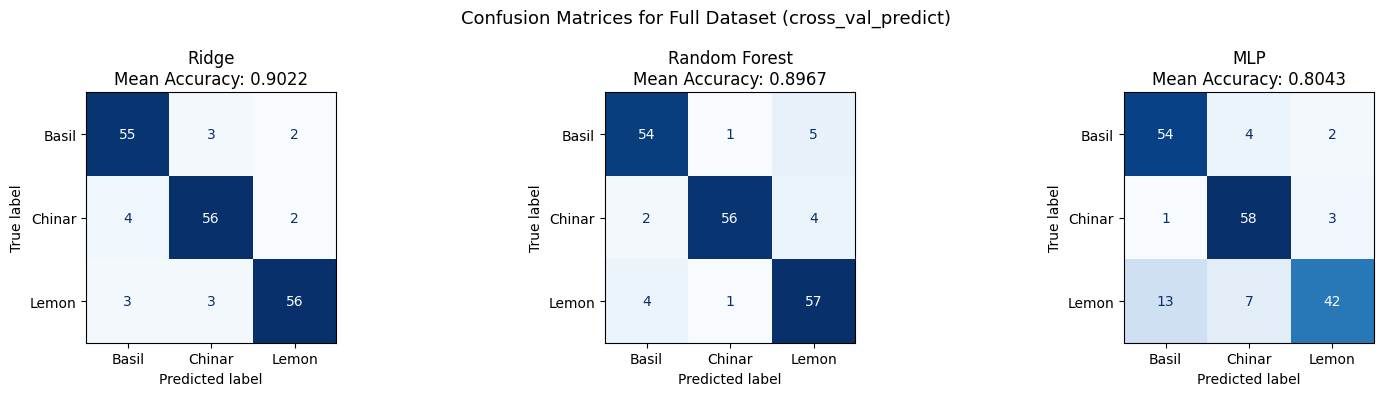

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

classifiers_final = {
    'Ridge':         results['Ridge']['model'],
    'Random Forest': results['Random Forest']['model'],
    'MLP':           results['MLP']['model']
}

for ax, (name, model) in zip(axes, classifiers_final.items()):
    # Predict across all samples using cross-validation
    y_pred = cross_val_predict(model, X, y_encoded, cv=outer_cv)
    cm = confusion_matrix(y_encoded, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=folders).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f"{name}\nMean Accuracy: {nested_results[name]['mean']:.4f}")

plt.suptitle('Confusion Matrices for Full Dataset (cross_val_predict)', fontsize=13)
plt.tight_layout()
plt.show()

#### Performance Summary:

Ridge: 0.9022 (+/- 0.0237) - best and most stable

Random Forest: 0.8967 (+/- 0.0518) - good but more variance

MLP: 0.8043 (+/- 0.0583) - weakest and least stable

#### Confusion Matrix Analysis:

Ridge performs very well overall. 55/60 Basil, 56/62 Chinar, 56/62 Lemon correct. Misclassifications are spread evenly across classes with no single problematic pair, suggesting the linear model generalises cleanly across all three classes.

Random Forest is very close to Ridge with 54/60 Basil, 56/62 Chinar, 57/62 Lemon. The main weakness is Basil, where 5 samples are misclassified as Lemon, consistent with the PCA showing these two classes overlapping in the center.

MLP handles Basil and Chinar reasonably well (54/60 and 58/62) but struggles significantly with Lemon. Only 42/62 correctly classified, with 13 misclassified as Basil and 7 as Chinar. This confirms MLP struggles with the overlapping Lemon class on a small dataset.

- Lemon is consistently the hardest class across all classifiers which matches PCA and histogram findings
- Chinar is the easiest class. All three models classify it well
- Ridge and Random Forest perform similarly, with Ridge having a slight edge in stability
- MLP's Lemon recall is notably lower than the other classifiers

In [17]:
# Classification reports using full dataset predictions (consistent with confusion matrix)
for name, res in nested_results.items():
    y_pred = cross_val_predict(res['model'], X, y_encoded, cv=outer_cv)
    print(f"\n{name} - Classification Report:")
    print(classification_report(y_encoded, y_pred, target_names=folders))


Ridge - Classification Report:
              precision    recall  f1-score   support

       Basil       0.87      0.92      0.89        60
      Chinar       0.90      0.89      0.89        62
       Lemon       0.93      0.90      0.92        62

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.90      0.90      0.90       184


Random Forest - Classification Report:
              precision    recall  f1-score   support

       Basil       0.88      0.88      0.88        60
      Chinar       0.98      0.89      0.93        62
       Lemon       0.85      0.94      0.89        62

    accuracy                           0.90       184
   macro avg       0.91      0.90      0.90       184
weighted avg       0.91      0.90      0.90       184


MLP - Classification Report:
              precision    recall  f1-score   support

       Basil       0.87      0.78      0.82        60
      Chinar       0.79    

#### Classification Report Analysis:

Ridge is the most balanced classifier with consistent scores across all three classes. Lemon achieves the highest precision (0.93) meaning few false Lemon predictions, while Basil has the highest recall (0.92) meaning most Basil samples are correctly found. F1-scores range from 0.89 to 0.92 with no single class being noticeably neglected. Overall accuracy of 0.90.

Random Forest matches Ridge's overall accuracy (0.90) but with a different error pattern. Chinar stands out with near-perfect precision (0.98), meaning RF almost never incorrectly predicts Chinar. However Lemon recall (0.94) is the highest across all classifiers for that class. Basil is the weakest point with both precision and recall at 0.88, giving the lowest F1 (0.88) of any class in this classifier.

MLP achieves the lowest overall accuracy (0.84) and shows the most uneven class performance. Chinar recall is very high (0.97) but paired with low precision (0.79), meaning MLP over-predicts Chinar by pulling in samples from other classes. Basil and Lemon both suffer with recalls of 0.78 and 0.77 respectively, meaning roughly one in five samples from each class is misclassified. This is consistent with the confusion matrix showing MLP struggling most with Lemon and Basil separation.

Overall: Ridge and Random Forest perform comparably at 0.90 accuracy, but Ridge shows more even precision and recall across all classes. MLP lags behind at 0.84 with notably weaker recall on Basil and Lemon.

# Discussion

#### Which classifier performed best and why?
Ridge Classifier achieved the best performance with a mean nested CV accuracy of 90.22%, outperforming Random Forest (89.67%) and MLP (80.43%). This is consistent with the small dataset size of 184 images. Linear models like Ridge generalise well with limited data because they have fewer parameters to tune and are less prone to overfitting. The low standard deviation across outer folds also indicates Ridge produces stable, reliable predictions regardless of how the data is split. MLP performed worst despite being the most complex model, which is a classic sign of insufficient training data for a neural network.

#### What are the limitations of the approach?

The dataset is very small (184 images across 3 classes, 60 or 62 per class), which limits the reliability of all performance estimates and particularly disadvantages MLP. The feature set relies heavily on color information and if images were taken under different lighting conditions, color features would become unreliable. Template matching depends on the quality of the selected template image; a poor centroid representative could weaken those features. GLCM features showed limited discriminative power individually, suggesting the texture representation may not capture the most relevant leaf surface properties. Finally, each image is processed independently with no spatial or shape-based features such as leaf contour or edge descriptors.

#### How could the results be improved?

The most straightforward improvement would be collecting more training images. With only around 60 images per class, all classifiers are working with limited data. Expanding the dataset would benefit all three models.

The hyperparameter search could also be extended by testing a wider range of values. For example, Ridge was only tested with 4 alpha values. Trying more options might find a better regularization strength.

Feature selection could be explored. Since color means already dominate and some features like glcm_d1_v showed almost no discriminative power, removing the weakest features might reduce noise and improve classification. PCA dimensionality reduction before classification is another simple option worth trying given the high correlation between color features observed in the pairplot.

Finally, the template selection strategy could be revisited. Instead of using the image closest to the centroid, trying multiple templates per class and taking the average score might produce more robust template matching features.

#### References:

https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.RidgeClassifier.html

https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

https://mahotas.readthedocs.io/en/latest/features.html

https://docs.opencv.org/4.x/d4/dc6/tutorial_py_template_matching.html

https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.graycomatrix